# EuroSAT RGB — Exploratory Data Analysis

## 1. Objective

This notebook explores the EuroSAT RGB dataset before model development.

The goal is to understand the dataset structure, class distribution, image properties, and potential data quality issues.

## 2. Research Questions

- How many images and land cover categories are available?
- How are images distributed across classes?
- What are the dimensions, colour channels, and file formats?
- What visual differences can be observed between categories?
- Are there any data quality issues that should be considered before training?

## 3. Dataset Overview

EuroSAT RGB is a labelled satellite imagery dataset based on Sentinel-2 data.

The dataset is expected to contain approximately 27,000 images across ten land cover categories. The RGB images have a resolution of 64 × 64 pixels.

## 4. Analysis Workflow

1. Inspect the Python environment and dataset paths.
2. Validate the dataset structure.
3. Analyse the class distribution.
4. Inspect image properties and representative samples.
5. Summarise the main findings and implications for model development.

In [11]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import PIL
from IPython.display import display
from PIL import Image

print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"Matplotlib version: {matplotlib.__version__}")
print(f"Pillow version: {PIL.__version__}")

Python version: 3.11.9
pandas version: 3.1.0
Matplotlib version: 3.11.2
Pillow version: 12.3.0


In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_DIR = PROJECT_ROOT / "data" / "raw" / "EuroSAT_RGB"

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset directory: {DATASET_DIR}")

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_DIR}. "
        "Run scripts/prepare_dataset.py first."
    )

Project root: c:\Users\carla.lamas\Documents\P-Personal\landcover-lab
Dataset directory: c:\Users\carla.lamas\Documents\P-Personal\landcover-lab\data\raw\EuroSAT_RGB


In [3]:
class_dirs = sorted(
    path for path in DATASET_DIR.iterdir()
    if path.is_dir()
)

image_paths_by_class = {
    class_dir.name: sorted(
        path
        for path in class_dir.iterdir()
        if path.is_file() and path.suffix.lower() == ".jpg"
    )
    for class_dir in class_dirs
}

dataset_summary = pd.DataFrame(
    {
        "class": list(image_paths_by_class.keys()),
        "image_count": [
            len(paths) for paths in image_paths_by_class.values()
        ],
    }
)

print(f"Number of classes: {len(class_dirs)}")
print(f"Total images: {dataset_summary['image_count'].sum():,}")

display(dataset_summary)

Number of classes: 10
Total images: 27,000


,class,image_count
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


In [4]:
EXPECTED_COUNTS = {
    "AnnualCrop": 3_000,
    "Forest": 3_000,
    "HerbaceousVegetation": 3_000,
    "Highway": 2_500,
    "Industrial": 2_500,
    "Pasture": 2_000,
    "PermanentCrop": 2_500,
    "Residential": 3_000,
    "River": 2_500,
    "SeaLake": 3_000,
}

dataset_summary["expected_count"] = (
    dataset_summary["class"].map(EXPECTED_COUNTS)
)

dataset_summary["matches_expected"] = (
    dataset_summary["image_count"]
    == dataset_summary["expected_count"]
)

display(dataset_summary)

print(
    "All class counts match the expected distribution:",
    dataset_summary["matches_expected"].all(),
)

,class,image_count,expected_count,matches_expected
0,AnnualCrop,3000,3000,True
1,Forest,3000,3000,True
2,HerbaceousVegetation,3000,3000,True
3,Highway,2500,2500,True
4,Industrial,2500,2500,True
5,Pasture,2000,2000,True
6,PermanentCrop,2500,2500,True
7,Residential,3000,3000,True
8,River,2500,2500,True
9,SeaLake,3000,3000,True


All class counts match the expected distribution: True


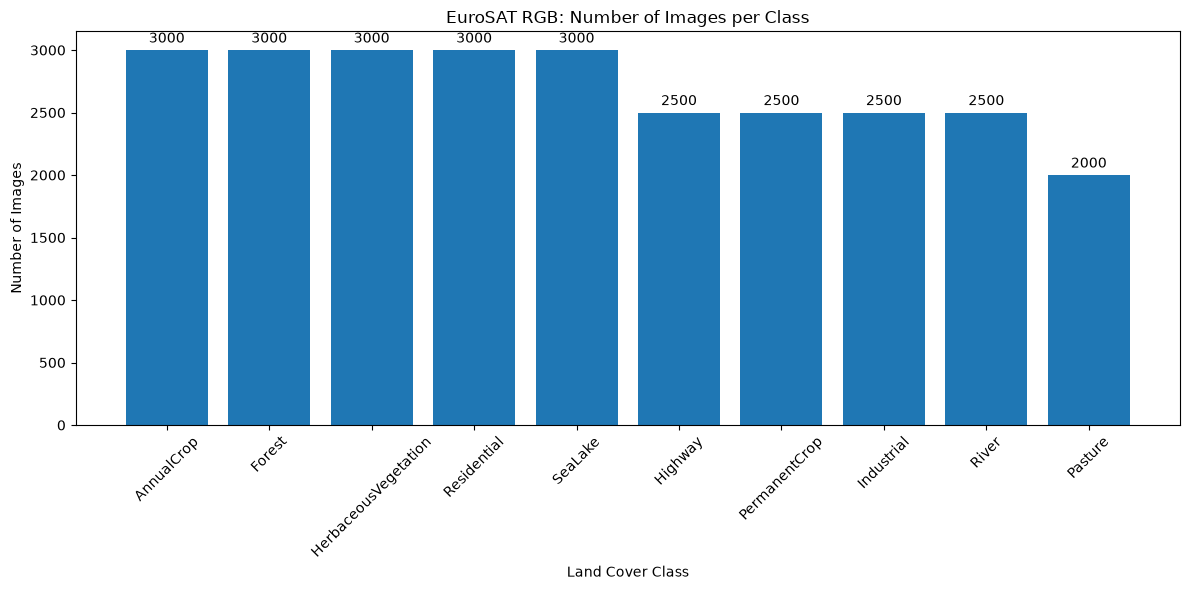

In [8]:
plot_data = dataset_summary.sort_values(
    "image_count",
    ascending=False,
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    plot_data["class"],
    plot_data["image_count"],
)

ax.set_title("EuroSAT RGB: Number of Images per Class")
ax.set_xlabel("Land Cover Class")
ax.set_ylabel("Number of Images")
ax.tick_params(axis="x", rotation=45)

ax.bar_label(bars, padding=3)

fig.tight_layout()

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "class_distribution.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

## 5. Image Properties

This section examines the technical properties of the image files, including image dimensions, colour modes, file formats, and potential reading errors.

Understanding these properties helps verify that the dataset is suitable for the planned classification experiments.

In [6]:
from collections import Counter

image_records = []
unreadable_images = []

for class_name, paths in image_paths_by_class.items():
    for image_path in paths:
        try:
            with Image.open(image_path) as image:
                image_records.append(
                    {
                        "class": class_name,
                        "filename": image_path.name,
                        "width": image.width,
                        "height": image.height,
                        "mode": image.mode,
                        "format": image.format,
                    }
                )
        except (OSError, ValueError) as error:
            unreadable_images.append(
                {
                    "path": str(image_path),
                    "error": str(error),
                }
            )

image_metadata = pd.DataFrame(image_records)

print(f"Images inspected: {len(image_metadata):,}")
print(f"Unreadable images: {len(unreadable_images)}")

print("\nImage dimensions:")
display(
    image_metadata.groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
)

print("\nColour modes:")
display(
    image_metadata["mode"]
    .value_counts()
    .rename_axis("mode")
    .reset_index(name="image_count")
)

print("\nFile formats:")
display(
    image_metadata["format"]
    .value_counts()
    .rename_axis("format")
    .reset_index(name="image_count")
)

if unreadable_images:
    print("\nExamples of unreadable images:")
    display(pd.DataFrame(unreadable_images).head(10))


Images inspected: 27,000
Unreadable images: 0

Image dimensions:


,width,height,image_count
0,64,64,27000



Colour modes:


,mode,image_count
0,RGB,27000



File formats:


,format,image_count
0,JPEG,27000


## 6. Visual Inspection

A representative sample from each land cover category is displayed below.

This inspection provides an initial understanding of the visual characteristics of each class and helps identify categories that may be difficult to distinguish.


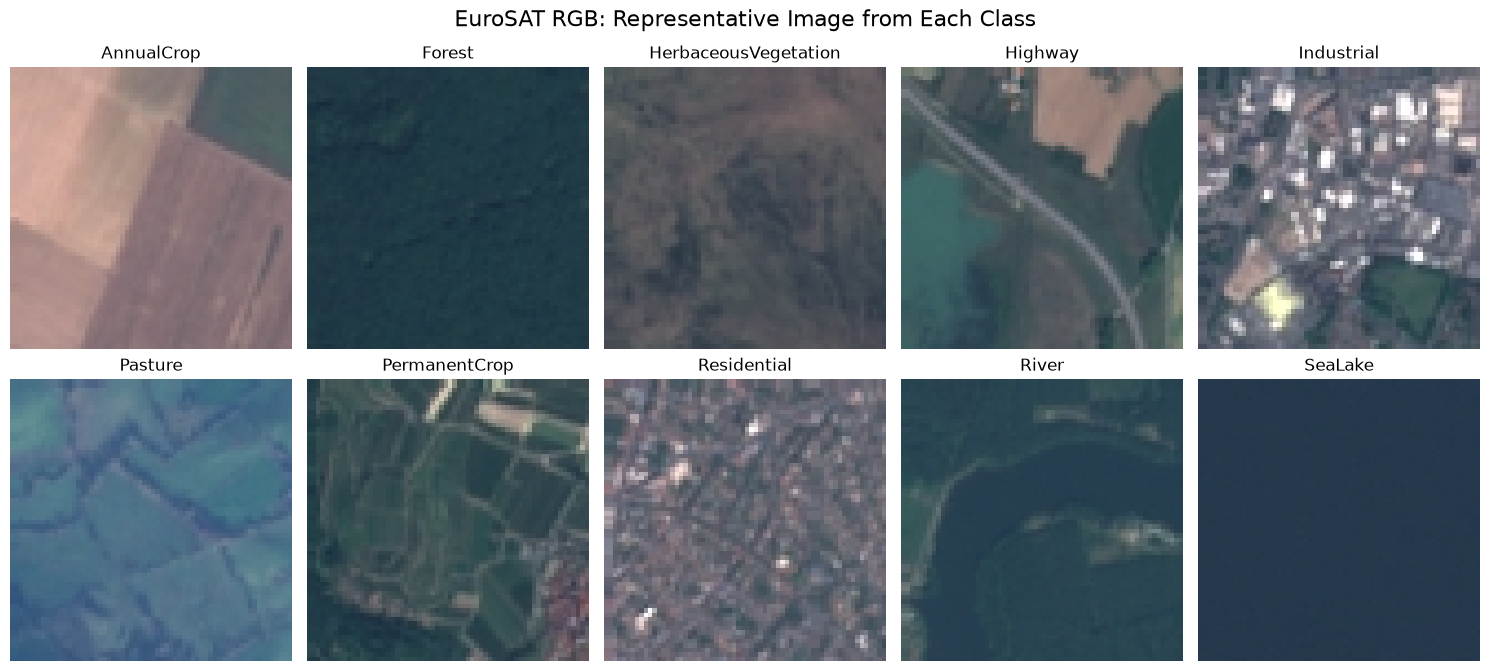

In [10]:
import random

rng = random.Random(42)

class_names = sorted(image_paths_by_class)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.flatten()

for ax, class_name in zip(axes, class_names):
    image_path = rng.choice(image_paths_by_class[class_name])

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

fig.suptitle(
    "EuroSAT RGB: Representative Image from Each Class",
    fontsize=16,
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "representative_samples.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

## 7. Preliminary Findings

### Dataset Structure

- The dataset contains 27,000 images across ten land cover categories.
- All ten categories match the expected image counts.

### Class Distribution

- The number of images per class ranges from 2,000 to 3,000.
- `Pasture` is the smallest class, with 2,000 images.
- `AnnualCrop`, `Forest`, `HerbaceousVegetation`, `Residential`, and `SeaLake` contain 3,000 images each.
- The dataset is not perfectly balanced, so class-specific metrics will be important during model evaluation.

### Image Properties

- All 27,000 images have a resolution of 64 × 64 pixels.
- All images use the RGB colour mode.
- All files are in JPEG format.
- No unreadable images were detected during inspection.

### Data Integrity

The image-level inspection completed successfully. No unreadable files were found, and the observed image properties were consistent across the dataset.

### Implications for Modelling

- The consistent image dimensions simplify the initial data pipeline.
- The RGB representation is suitable for the planned computer vision and CNN experiments.
- The class distribution should be considered when defining evaluation metrics and stratified data splits.
- The visual similarity between certain categories should be investigated before comparing classification models.

### Visual Inspection

The initial visual inspection reveals several potentially challenging class pairs:

- **Agricultural classes:** AnnualCrop, Pasture, and PermanentCrop may share similar colours and spatial textures.
- **Built-up areas:** Industrial and Residential images may contain overlapping visual patterns.
- **Water bodies:** River and SeaLake images may share similar colour distributions, making shape and spatial context relevant.

These observations are preliminary hypotheses based on one sampled image per class. A larger sample and model evaluation are required to determine whether these similarities lead to classification errors.

The RGB images have a relatively low spatial resolution of 64 × 64 pixels. This limits the amount of fine-grained detail available to the models.

### Next Steps

- Inspect representative images from all ten categories.
- Save the main exploratory figures.
- Define a reproducible training, validation, and test splitting strategy before model training.

## 8. Pixel Intensity Analysis

RGB images encode colour information as numerical pixel intensities.

This section examines the global distribution of pixel values across the dataset and calculates the mean and standard deviation for each colour channel.

These statistics will help characterize the input data and provide context for future preprocessing and normalization decisions.

In [12]:
channel_sum = np.zeros(3, dtype=np.float64)
channel_squared_sum = np.zeros(3, dtype=np.float64)
pixel_count = 0

for paths in image_paths_by_class.values():
    for image_path in paths:
        with Image.open(image_path) as image:
            pixels = np.asarray(
                image.convert("RGB"),
                dtype=np.float64,
            )

        channel_sum += pixels.sum(axis=(0, 1))
        channel_squared_sum += np.square(pixels).sum(axis=(0, 1))
        pixel_count += pixels.shape[0] * pixels.shape[1]

channel_mean = channel_sum / pixel_count

channel_variance = (
    channel_squared_sum / pixel_count
    - np.square(channel_mean)
)

channel_std = np.sqrt(np.maximum(channel_variance, 0))

pixel_statistics = pd.DataFrame(
    {
        "channel": ["Red", "Green", "Blue"],
        "mean": channel_mean,
        "standard_deviation": channel_std,
        "mean_normalized": channel_mean / 255.0,
        "std_normalized": channel_std / 255.0,
    }
)

display(pixel_statistics.round(4))

print(f"Total images processed: {sum(map(len, image_paths_by_class.values())):,}")
print(f"Total pixels processed: {pixel_count:,}")

,channel,mean,standard_deviation,mean_normalized,std_normalized
0,Red,87.8159,51.6785,0.3444,0.2027
1,Green,96.9742,34.9086,0.3803,0.1369
2,Blue,103.9814,29.4653,0.4078,0.1156


Total images processed: 27,000
Total pixels processed: 110,592,000


### Pixel Intensity Findings

The global pixel intensity statistics reveal differences across the three RGB channels:

- **Red:** mean intensity of 87.82 and standard deviation of 51.68.
- **Green:** mean intensity of 96.97 and standard deviation of 34.91.
- **Blue:** mean intensity of 103.98 and standard deviation of 29.47.

The Blue channel has the highest global mean intensity, while the Red channel exhibits the greatest variability across all pixels.

These statistics summarize the distribution of encoded RGB intensities across the dataset. They do not represent direct measurements of surface reflectance.

The global statistics provide an initial description of the input data. Further analysis of the intensity distributions and class-specific patterns may help inform preprocessing decisions.

## 9. Pixel Intensity Distributions

This section examines the distribution of RGB pixel intensities across the dataset.

Histograms provide more detail than global summary statistics by showing which intensity values occur most frequently in each colour channel.

In [ ]:
channel_names = ["Red", "Green", "Blue"]
histogram_counts = np.zeros((3, 256), dtype=np.int64)

for paths in image_paths_by_class.values():
    for image_path in paths:
        with Image.open(image_path) as image:
            pixels = np.asarray(
                image.convert("RGB"),
                dtype=np.uint8,
            )

        for channel_index in range(3):
            histogram_counts[channel_index] += np.bincount(
                pixels[:, :, channel_index].ravel(),
                minlength=256,
            )

histogram_frequencies = histogram_counts / pixel_count

fig, ax = plt.subplots(figsize=(12, 6))

intensity_values = np.arange(256)

for channel_index, channel_name in enumerate(channel_names):
    ax.plot(
        intensity_values,
        histogram_frequencies[channel_index],
        label=channel_name,
    )

ax.set_title("EuroSAT RGB: Pixel Intensity Distributions")
ax.set_xlabel("Pixel Intensity (0–255)")
ax.set_ylabel("Proportion of Pixels")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    FIGURES_DIR / "pixel_intensity_distributions.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()